## Gavin Hockin Bluesky API
# Hypothesis: Accounts with larger follower counts recieve fewer likes per follow (a lower engagement rate) than accounts with smaller follower counts. 
Theoretical applications: You could use this application if you were a creator decising whether a bigger audience actually means more engagement.

Statistical applications: A group comparison and correlation.

Variabls: Follower count, likes per post, reposts per post, replies per post, and engagement rate.

## Endpoint 1: getProfile
It will take an account's handle and return the profile information. Follower count is the core predictor in the hypothesis, and this endpoint returns it directly for us. 

## Endpoint 2: getAuthorFeed
It returns an account's recent posts. It is suitable because engagement counts exist at the post level, so this endpoint is the only way to calculate average likes per post for each account. 

## How the 2 endpoints combine
I will call getProfile once per account, and then call getAuthorFeed for the same accounts. I will average the engagement metrics per account using groupby(), then I can merge the two DataFrames using the pandas library. 

## Reliability of the data
The data is reliable because it comes directly from Bluesky's own servers. Also, both endpoints are public and use a consistent, documented struction. The data could be unreliable for the reasons of uneven engagement windows (recent posts haven't finished accumulating likes) and also inflated or inactive followers. 

## Limitations
The limitations of this data come from the fact that it is recent posts only. getAuthorFeed returns posts in reverse chronological order. I'll collect a fixed number of recent posts per account which means I'm measuring recent behavior, not an account's full history. 

## Effect on Conclusions
Because of these limitations, the patterns I may find will show just an association within my sample, not actual proof. So you must treat my results as some form of evidence instead of a fact.

importing requests and pandas, also checking that print will return with "200"

In [7]:
import requests
import pandas as pd

url = "https://public.api.bsky.app/xrpc/app.bsky.actor.getProfile"

params= {
    "actor":"bsky.app"
}
response = requests.get(url,params=params, timeout=15)

print(response.status_code)

200


In [10]:
#Creating a base for the URL, also calling the two accounts I found (one being a large account and one being a smaller account)
BASE = "https://public.api.bsky.app/xrpc"
accounts = ["fravery.bsky.social", "transientmind.bsky.social"]
profiles = []

for account in accounts:
    response = requests.get(
        BASE + "/app.bsky.actor.getProfile",
        params={"actor": account},
        timeout=15
    )
    print(account, response.status_code)

    data = response.json()
    profiles.append({
        "did": data["did"],
        "handle": data["handle"],
        "followers": data.get("followersCount", 0),
        "following": data.get("followsCount", 0),
        "total_posts": data.get("postsCount", 0)
    })

#Creating a DataFrame for both profiles to show followers, following, and total posts
profiles_df = pd.DataFrame(profiles)
display(profiles_df)

fravery.bsky.social 200
transientmind.bsky.social 200


,did,handle,followers,following,total_posts
0,did:plc:hyv5w3p74clcq6bc7srpqpta,fravery.bsky.social,10548,149,6879
1,did:plc:uabnjlrdukppgmgedyh4qw32,transientmind.bsky.social,156,462,173


In [11]:
feed_url = BASE + "/app.bsky.feed.getAuthorFeed"

response = requests.get(
    feed_url,
    params={
        "actor": profiles_df.loc[0, "did"],
        "limit": 30,
        "filter": "posts_no_replies"
    },
    timeout=15
)
response.raise_for_status()
sample = response.json()

print(sample.keys())
print(sample["feed"][0].keys())

dict_keys(['feed', 'cursor'])
dict_keys(['post'])


In [12]:
print(sample["feed"][0]["post"].keys())

dict_keys(['uri', 'cid', 'author', 'record', 'embed', 'bookmarkCount', 'replyCount', 'repostCount', 'likeCount', 'quoteCount', 'indexedAt', 'labels'])


In [13]:
#Running this code to double check how many posts came out, since it may be fewer than 30
len(sample["feed"])

30

In [15]:
#I now want to look thorugh the feed for every account and build a DataFrame for posts.
post_frames = []

for profile in profiles:
    response = requests.get(
        feed_url,
        params={
            "actor": profile["did"],
            "limit": 30,
            "filter": "posts_no_replies"
        },
        timeout=15
    )
    response.raise_for_status()
    feed = response.json().get("feed", [])

    rows = [
        {
            "did": item["post"]["author"]["did"],
            "uri": item["post"]["uri"],
            "text": item["post"]["record"].get("text", ""),
            "likes": item["post"].get("likeCount", 0),
            "reposts": item["post"].get("repostCount", 0),
            "replies": item["post"].get("replyCount", 0),
            "created_at": item["post"]["record"].get("createdAt", "")
        }
        for item in feed
        if "reason" not in item
        and item["post"]["author"]["did"] == profile["did"]
    ]

    post_frames.append(pd.DataFrame(rows))

posts_df = pd.concat(post_frames, ignore_index=True)
display(posts_df.head())

#I had Claude help me with this section. I needed help knowing what to put in the rows and the for loop.

,did,uri,text,likes,reposts,replies,created_at
0,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"“If you truly love nature, you will find beaut...",32,8,0,2026-10-19T16:41:07.156Z
1,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"""Freedom does not consist only in following on...",2,1,0,2026-10-19T16:33:53.368Z
2,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"""Towering Storm""\n\nAcrylic on Panel\n\nBy Ame...",283,42,3,2026-10-19T13:49:40.246Z
3,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"Quiet Garden, Sergiu Ciochina, oil on canvas, ...",52,10,0,2026-10-19T13:32:06.855Z
4,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"""What is the point of repentance if it doesn't...",21,2,0,2026-10-19T12:59:28.359Z


In [16]:
#I now wnat to check my results and how many posts each account contributed
print(posts_df.groupby("did").size())

did
did:plc:hyv5w3p74clcq6bc7srpqpta    30
did:plc:uabnjlrdukppgmgedyh4qw32     7
dtype: int64


As you can see above, the smaller account can only contribute 7 posts compared to the larger accounts 30. I am going to keep the uneven sample size as this would natrually happen when comparing accounts of 2 different sizes.

In [17]:
#Merging the two DataFrames
combined_df = pd.merge(
    posts_df,
    profiles_df[["did", "handle", "followers"]],
    on="did",
    how="left",
    validate="many_to_one"
)

display(combined_df.head())
print(combined_df.shape)

,did,uri,text,likes,reposts,replies,created_at,handle,followers
0,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"“If you truly love nature, you will find beaut...",32,8,0,2026-10-19T16:41:07.156Z,fravery.bsky.social,10548
1,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"""Freedom does not consist only in following on...",2,1,0,2026-10-19T16:33:53.368Z,fravery.bsky.social,10548
2,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"""Towering Storm""\n\nAcrylic on Panel\n\nBy Ame...",283,42,3,2026-10-19T13:49:40.246Z,fravery.bsky.social,10548
3,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"Quiet Garden, Sergiu Ciochina, oil on canvas, ...",52,10,0,2026-10-19T13:32:06.855Z,fravery.bsky.social,10548
4,did:plc:hyv5w3p74clcq6bc7srpqpta,at://did:plc:hyv5w3p74clcq6bc7srpqpta/app.bsky...,"""What is the point of repentance if it doesn't...",21,2,0,2026-10-19T12:59:28.359Z,fravery.bsky.social,10548


(37, 9)


In [18]:
#Aggregate per account and calculate engagement rate
summary_df = (
    combined_df.groupby(["did", "handle"], as_index=False)
    .agg(
        followers=("followers", "first"),
        mean_likes=("likes", "mean"),
        median_likes=("likes", "median"),
        mean_reposts=("reposts", "mean"),
        posts_sampled=("uri", "count")
    )
    .sort_values("followers")
)

summary_df["engagement_rate"] = summary_df["mean_likes"] / summary_df["followers"]

display(summary_df)

#I also used Claude AI to help me build this code. I couldn't figure out the best way to calculate the engagement rate on my own.

,did,handle,followers,mean_likes,median_likes,mean_reposts,posts_sampled,engagement_rate
1,did:plc:uabnjlrdukppgmgedyh4qw32,transientmind.bsky.social,156,1.571429,2.0,0.000000,7,0.010073
0,did:plc:hyv5w3p74clcq6bc7srpqpta,fravery.bsky.social,10548,204.100000,185.0,33.133333,30,0.019350


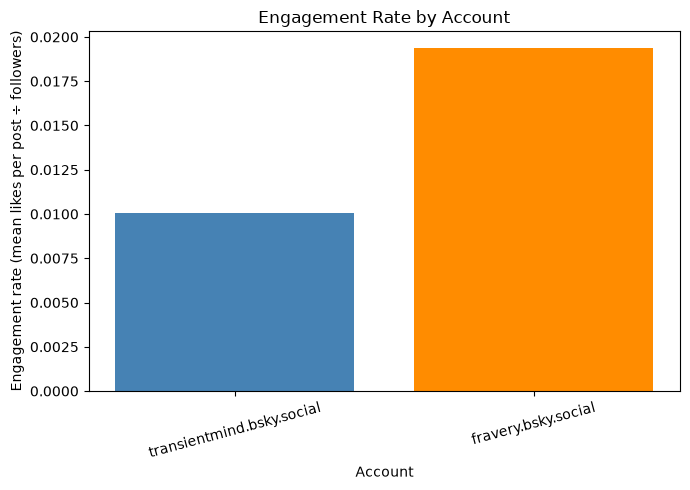

In [19]:
#Using Claude again, I want to make a visualization to show the engagement rate for each account
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.bar(summary_df["handle"], summary_df["engagement_rate"], color=["steelblue", "darkorange"])
plt.title("Engagement Rate by Account")
plt.xlabel("Account")
plt.ylabel("Engagement rate (mean likes per post ÷ followers)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Conclusion
In this sample, the account with the larger following had a higher engagement rate than the smaller one. My hypothesis is proved WRONG using this data. 

# Limitations
The sample size was the biggest problem when running this data. As I stated earlier, the smaller account could only contribute 7 posts to the data frame. This also contributed to the unever post counts. 

# Next Steps
The next steps I would take would be adding more accounts to each group, for example I would do 5 larger accounts (10,000+ followers) and 5 smaller accounts (under 1,000 followers). This would lead you to be able to collect more posts per group, meaning more data. 